<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/Friendship_Spectrum_Tree_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

Using Python 3.13.16 environment at: /usr
Checked 2 packages in 89ms


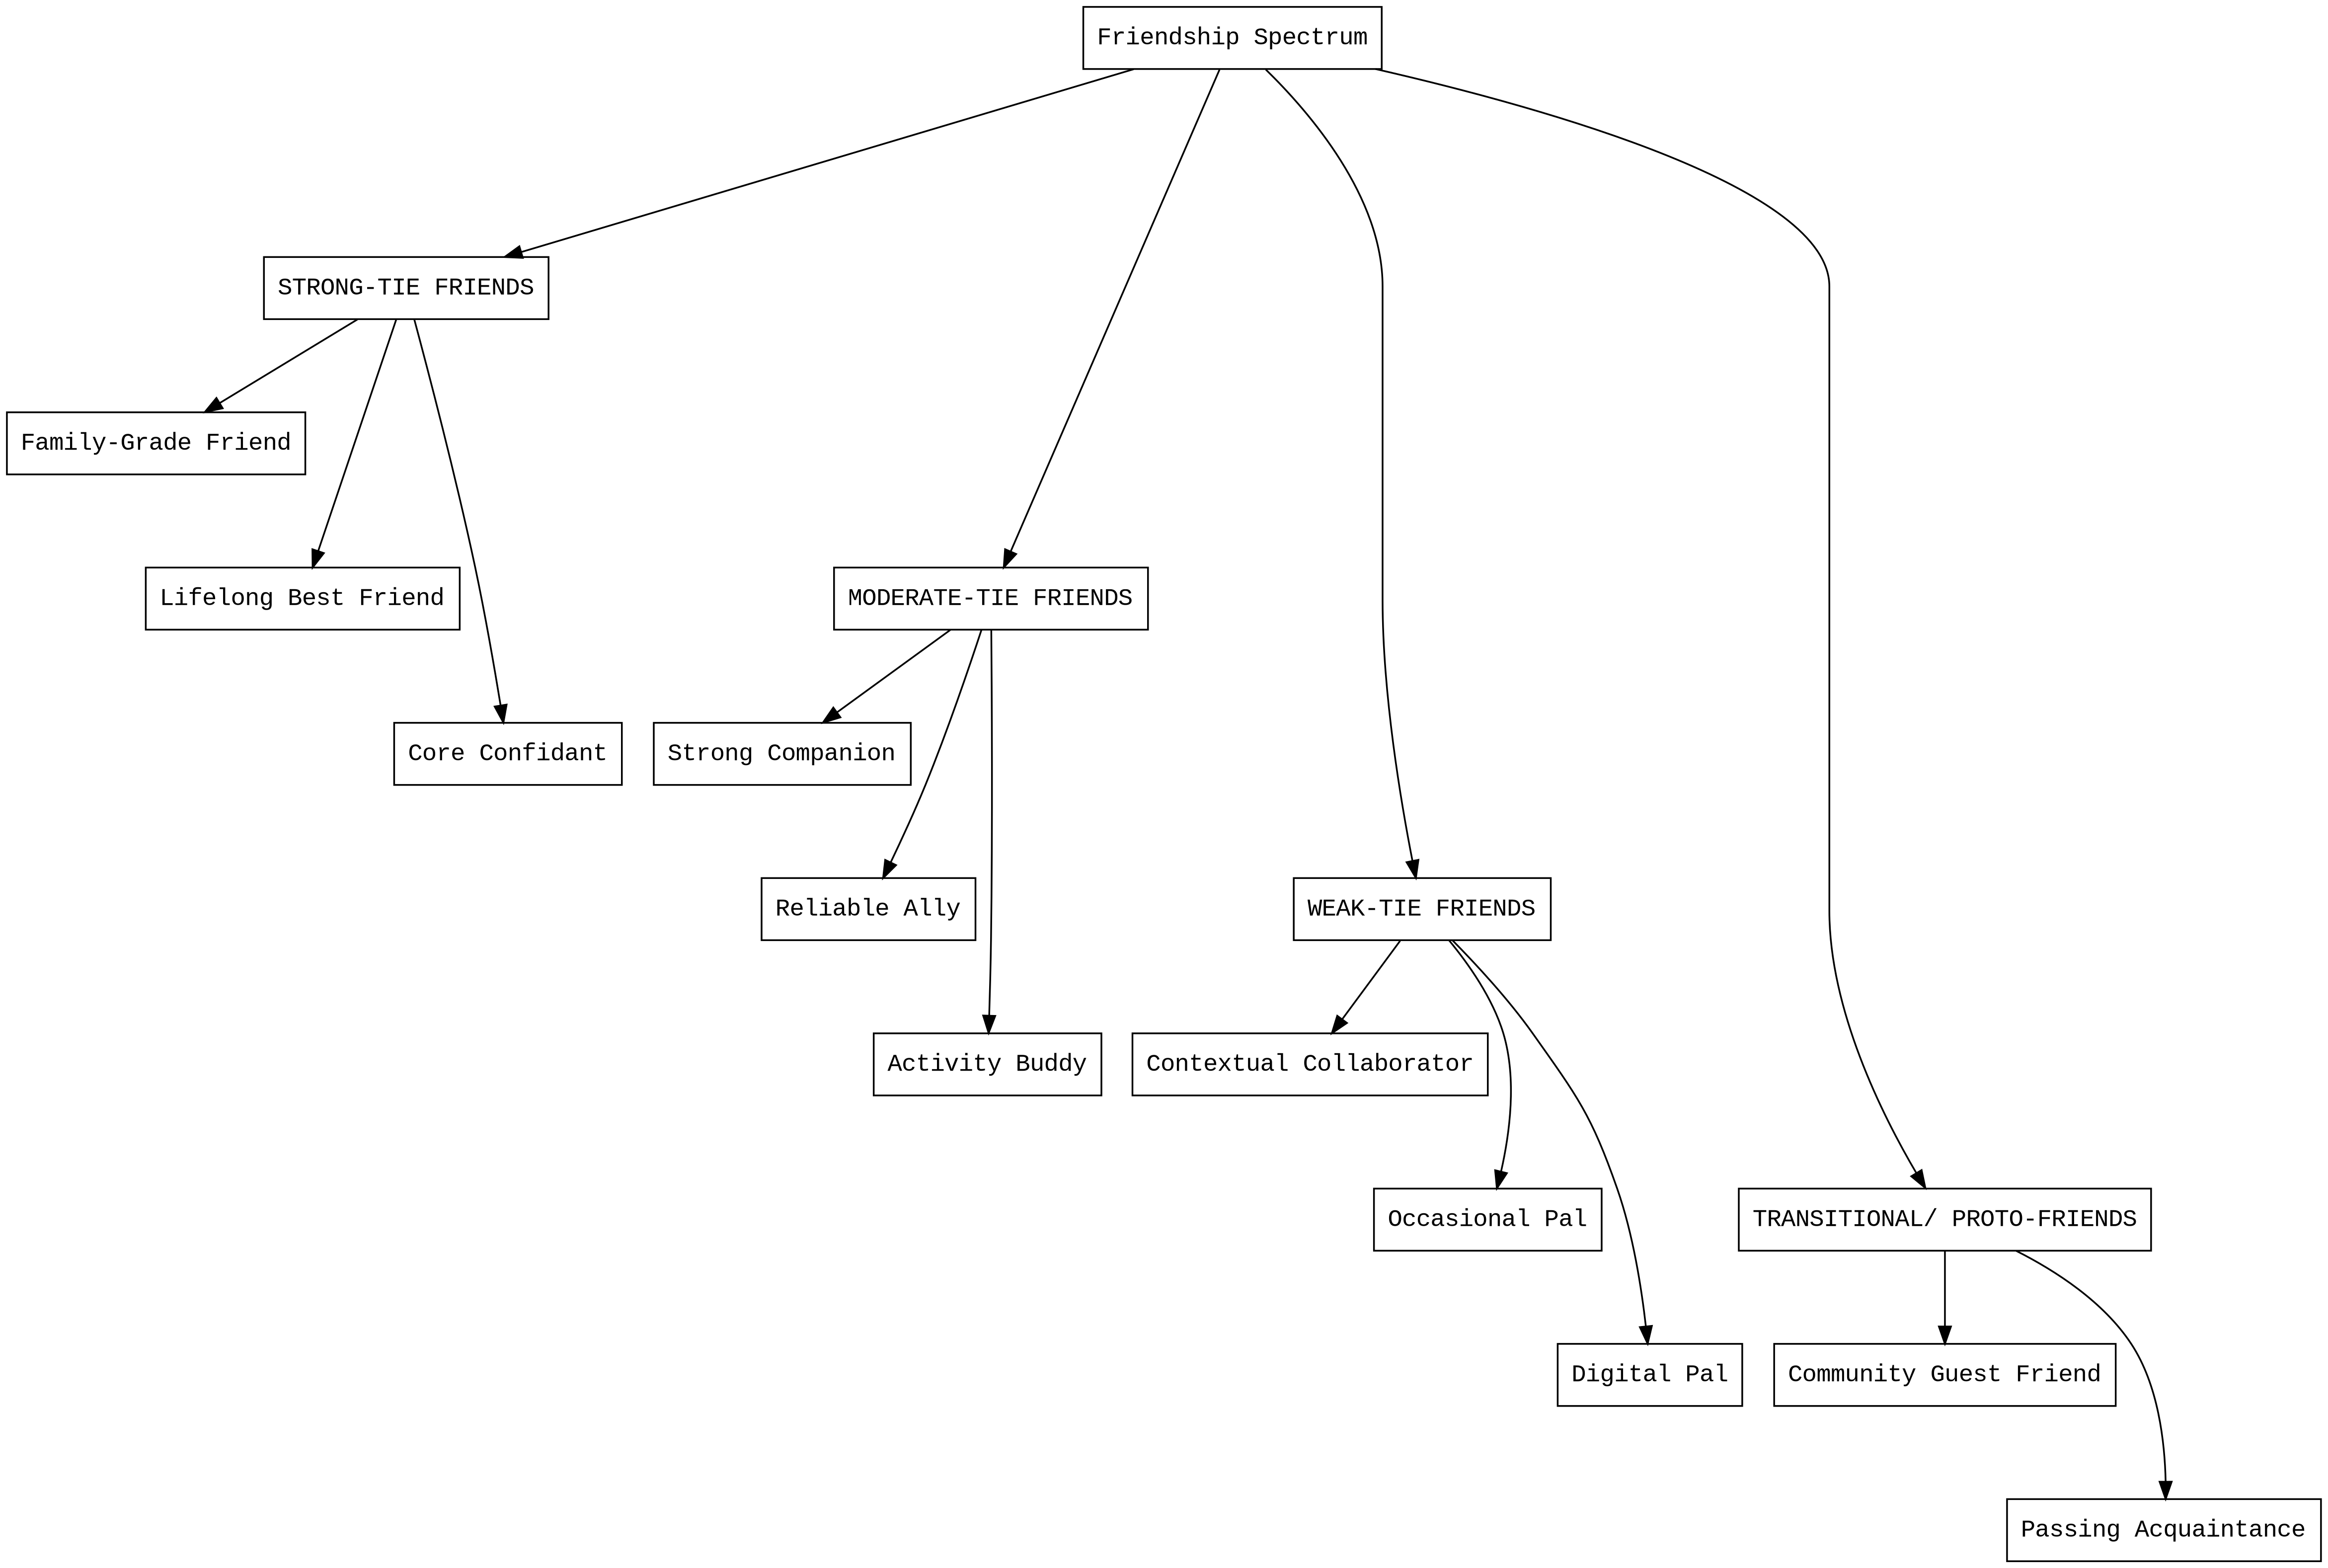

In [2]:
!uv pip install graphviz ipython

"""This script constructs a directed friendship spectrum graph and renders it as an in-memory object.

The graph avoids orthogonal edges and maintains an absolute monochrome aesthetic. Control parameters
defined at the module level dictate the precise font, resolution, and vertical spacing characteristics.
The script applies a hard character limit to each graphical node, cascades primary branches, and stretches
the diagram vertically.
"""

import graphviz
from IPython.display import display, Image

# Control Knobs
GRAPH_DPI = "250"
NODE_FONT = "DejaVu Sans"
NODE_FONT_WEIGHT = "normal"
EDGE_ROUTING = "spline"
NODE_SHAPE = "box"
BACKGROUND_COLOR = "white"
FOREGROUND_COLOR = "black"
RANK_DIRECTION = "TB"
MAX_CHARACTERS_PER_LINE = 27
RANK_SEPARATION = "0.75"
VERTICAL_STAGGER_STEP = 2  # Multiplies the vertical drop distance between primary root branches

def wrap_text(text: str, max_width: int = MAX_CHARACTERS_PER_LINE) -> str:
    """Wraps text to a specified maximum width, hyphenating oversized strings.

    Args:
        text: The original string input.
        max_width: The maximum allowable characters per line.

    Returns:
        A formatted string featuring newline characters at proper intervals.
    """
    lines = []
    for paragraph in text.split('\n'):
        current_line = ""
        words = paragraph.split()
        for word in words:
            while len(word) > max_width:
                if current_line:
                    lines.append(current_line)
                    current_line = ""
                chunk = word[:max_width - 1] + "-"
                lines.append(chunk)
                word = word[max_width - 1:]

            if current_line:
                if len(current_line) + 1 + len(word) <= max_width:
                    current_line += " " + word
                else:
                    lines.append(current_line)
                    current_line = word
            else:
                current_line = word
        if current_line:
            lines.append(current_line)
    return '\n'.join(lines)

def build_friendship_tree() -> graphviz.Digraph:
    """Constructs the directed Graphviz object outlining the friendship spectrum hierarchy."""
    tree = graphviz.Digraph(format='png')

    tree.attr(dpi=GRAPH_DPI, splines=EDGE_ROUTING, bgcolor=BACKGROUND_COLOR, rankdir=RANK_DIRECTION, ranksep=RANK_SEPARATION)
    tree.attr('node', shape=NODE_SHAPE, style='solid', color=FOREGROUND_COLOR, fontcolor=FOREGROUND_COLOR, fontname=NODE_FONT)
    tree.attr('edge', color=FOREGROUND_COLOR, arrowhead='normal')

    tree.node('Root', wrap_text('Friendship Spectrum'))

    def add_staggered_leaves(parent_id: str, leaves: list) -> None:
        """Helper function to attach leaf nodes and stagger them vertically."""
        for idx, leaf_text in enumerate(leaves):
            leaf_id = f'{parent_id}_L_{idx}'
            tree.node(leaf_id, wrap_text(leaf_text))
            tree.edge(parent_id, leaf_id, minlen=str(idx + 1))

    categories = {
        'STRONG-TIE FRIENDS': [
            'Family-Grade Friend',
            'Lifelong Best Friend',
            'Core Confidant'
        ],
        'MODERATE-TIE FRIENDS': [
            'Strong Companion',
            'Reliable Ally',
            'Activity Buddy'
        ],
        'WEAK-TIE FRIENDS': [
            'Contextual Collaborator',
            'Occasional Pal',
            'Digital Pal'
        ],
        'TRANSITIONAL/ PROTO-FRIENDS': [
            'Community Guest Friend',
            'Passing Acquaintance'
        ]
    }

    for c_idx, (cat, leaves) in enumerate(categories.items()):
        c_id = f'Cat_{c_idx}'
        tree.node(c_id, wrap_text(cat))
        tree.edge('Root', c_id, minlen=str((c_idx + 1) * VERTICAL_STAGGER_STEP))
        add_staggered_leaves(c_id, leaves)

    return tree

def display_graph(tree: graphviz.Digraph) -> None:
    """Renders the graph in memory and displays the image without HTML wrappers."""
    binary_png = tree.pipe(format='png')
    display(Image(data=binary_png))

if __name__ == '__main__':
    friendship_tree = build_friendship_tree()
    display_graph(friendship_tree)